In [2]:
import pandas as pd

# 1. 열 이름 읽기 (Windows 줄바꿈 \r\n 대비 strip 처리)
with open("Faults27x7_var", "r") as f:
    cols = [line.strip() for line in f if line.strip()]

# 2. 데이터 읽기 (탭/공백 구분, 헤더 없음)
data = pd.read_csv("Faults.NNA", sep=r"\s+", header=None, names=cols)

# 3. 확인
print(data.shape)          # (1941, 34)
print(data.isna().sum().sum())  # 0

# 4. CSV로 저장
data.to_csv("steel_plates_faults.csv", index=False, encoding="utf-8-sig")

df = pd.read_csv("steel_plates_faults.csv")
display(df.head())
display(df.shape)         
display(df.isna().sum().sum())
display(df.info())

(1941, 34)
0


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


(1941, 34)

np.int64(0)

<class 'pandas.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   X_Minimum              1941 non-null   int64  
 1   X_Maximum              1941 non-null   int64  
 2   Y_Minimum              1941 non-null   int64  
 3   Y_Maximum              1941 non-null   int64  
 4   Pixels_Areas           1941 non-null   int64  
 5   X_Perimeter            1941 non-null   int64  
 6   Y_Perimeter            1941 non-null   int64  
 7   Sum_of_Luminosity      1941 non-null   int64  
 8   Minimum_of_Luminosity  1941 non-null   int64  
 9   Maximum_of_Luminosity  1941 non-null   int64  
 10  Length_of_Conveyer     1941 non-null   int64  
 11  TypeOfSteel_A300       1941 non-null   int64  
 12  TypeOfSteel_A400       1941 non-null   int64  
 13  Steel_Plate_Thickness  1941 non-null   int64  
 14  Edges_Index            1941 non-null   float64
 15  Empty_Index    

None

In [3]:
display(df["TypeOfSteel_A300"].value_counts())
display(df["TypeOfSteel_A400"].value_counts())
# 하나의 열로 합침  A300이면 0, A400이면 1
df["TypeOfSteel"] = df["TypeOfSteel_A400"] 
display(df["TypeOfSteel"].value_counts())

TypeOfSteel_A300
0    1164
1     777
Name: count, dtype: int64

TypeOfSteel_A400
1    1164
0     777
Name: count, dtype: int64

TypeOfSteel
1    1164
0     777
Name: count, dtype: int64

In [5]:
display(df.shape )                     # (1941, 34) 확인
display(df.dtypes.value_counts() )     # 자료형별 컬럼 수
display(df.nunique().sort_values() )    # 고유값 수가 적은 컬럼 → 범주형 후보
display(df.select_dtypes('object').columns )   # 문자형으로 잘못 읽힌 컬럼 확인

(1941, 35)

int64      22
float64    13
Name: count, dtype: int64

TypeOfSteel_A400            2
TypeOfSteel_A300            2
K_Scatch                    2
Pastry                      2
Dirtiness                   2
Stains                      2
Z_Scratch                   2
Bumps                       2
Other_Faults                2
TypeOfSteel                 2
Outside_Global_Index        3
Steel_Plate_Thickness      24
Length_of_Conveyer         84
Maximum_of_Luminosity     100
Minimum_of_Luminosity     161
Log_X_Index               183
Log_Y_Index               217
Y_Perimeter               317
SigmoidOfAreas            388
X_Perimeter               399
Outside_X_Index           454
Edges_Y_Index             648
Square_Index              770
Edges_X_Index             818
LogOfAreas                914
Orientation_Index         918
Pixels_Areas              920
X_Minimum                 962
X_Maximum                 994
Empty_Index              1338
Edges_Index              1387
Luminosity_Index         1522
Sum_of_Luminosity        1909
Y_Minimum 

Index([], dtype='str')

,컬럼,고유값 수,왜도,이상치 건수,이상치 비율(%),하한,상한,로그 후 이상치
7,Sum_of_Luminosity,1909,7.73,399,20.56,-100711.500,193244.500,25.0
4,Pixels_Areas,920,14.08,395,20.35,-1023.000,1929.000,6.0
15,Outside_X_Index,454,5.18,370,19.06,-0.019,0.049,31.0
5,X_Perimeter,399,21.54,352,18.13,-88.500,187.500,5.0
11,Steel_Plate_Thickness,24,2.21,240,12.36,-20.000,140.000,47.0
6,Y_Perimeter,317,39.29,179,9.22,-92.000,188.000,1.0
9,Maximum_of_Luminosity,100,1.29,146,7.52,100.000,164.000,190.0
23,Luminosity_Index,1522,0.68,134,6.90,-0.388,0.126,NaN
2,Y_Minimum,1939,2.81,81,4.17,-2096477.000,4750803.000,47.0
3,Y_Maximum,1940,2.81,81,4.17,-2096423.500,4750788.500,47.0


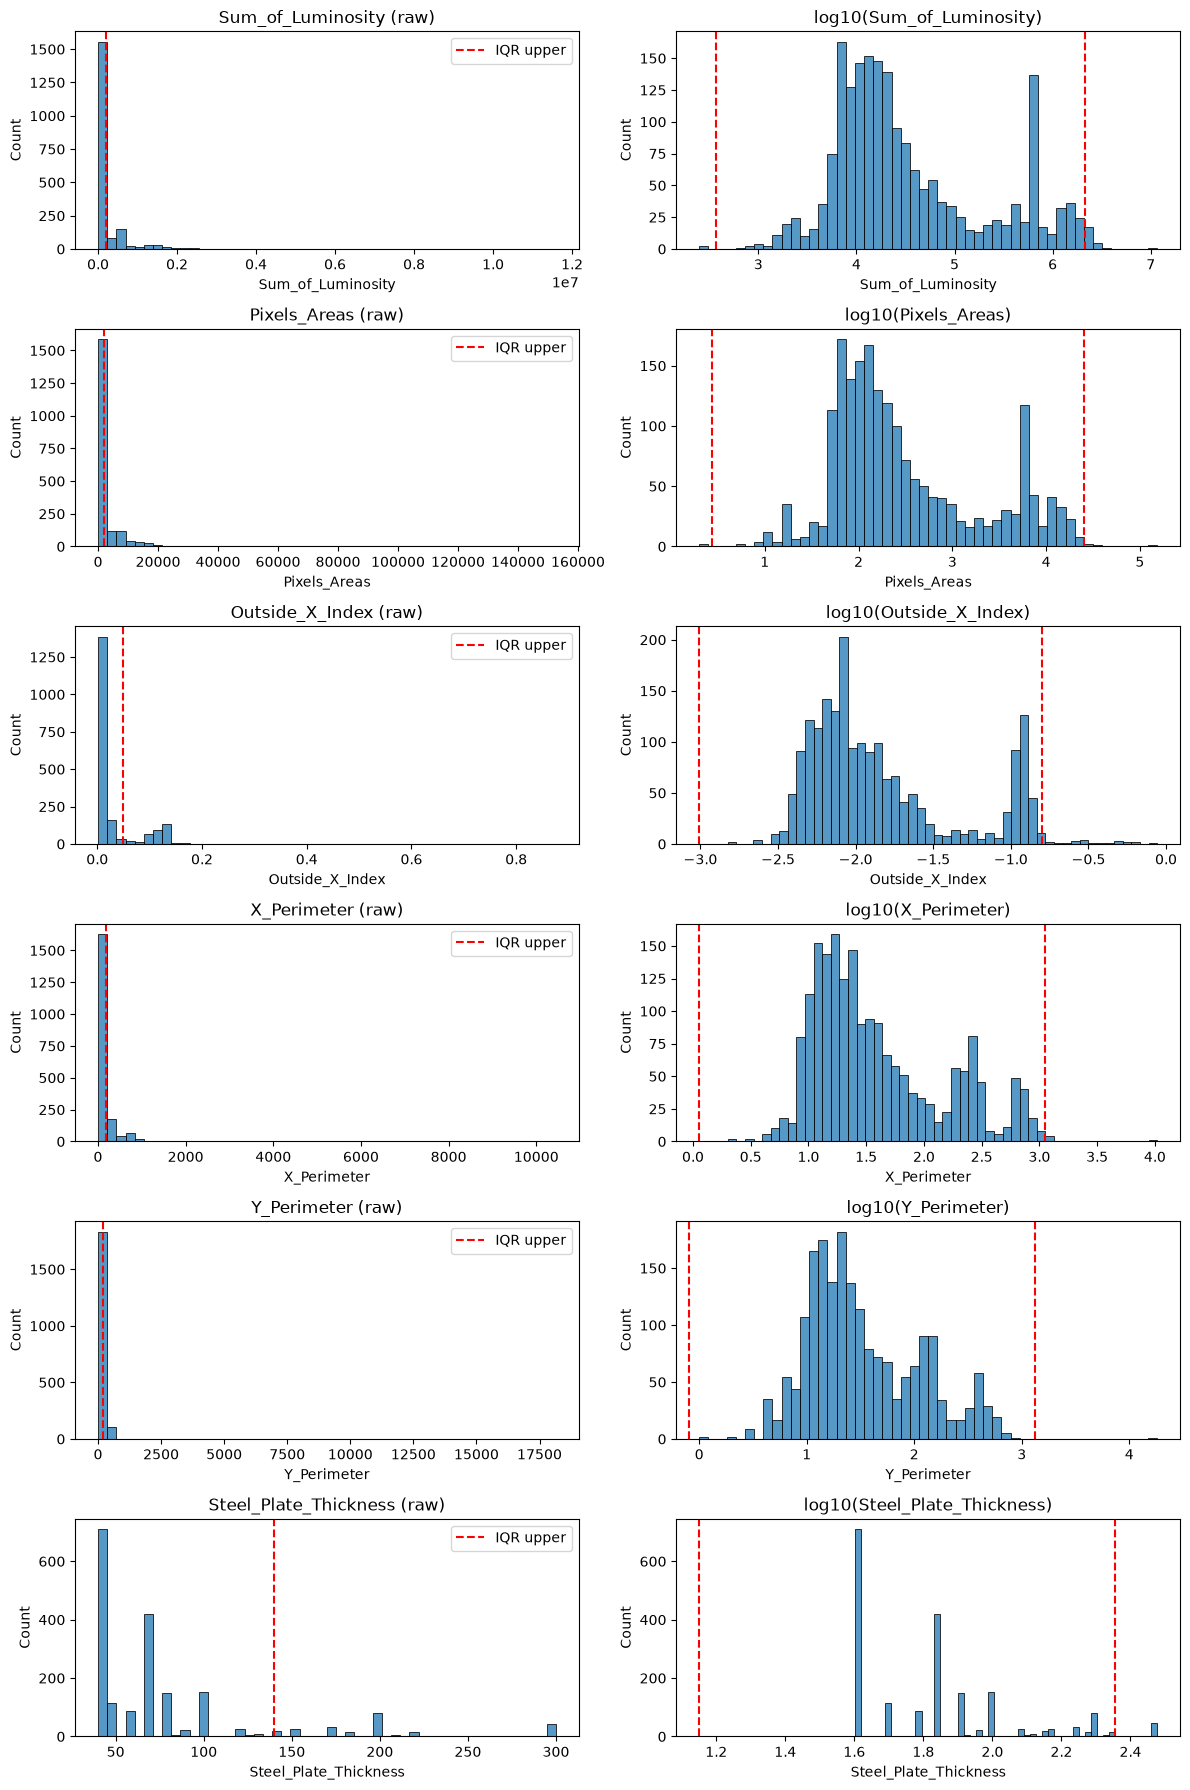

,전체 건수,이상치 보유 건수,유형 내 이상치 비율(%)
Fault_Type,,,
K_Scatch,391,368,94.1
Other_Faults,673,284,42.2
Pastry,158,55,34.8
Z_Scratch,190,40,21.1
Bumps,402,68,16.9
Dirtiness,55,9,16.4
Stains,72,0,0.0


Fault_Type,Bumps,Dirtiness,K_Scatch,Other_Faults,Pastry,Stains,Z_Scratch
Sum_of_Luminosity,1.5,0.0,82.5,10.5,2.8,0.0,2.8
Pixels_Areas,1.3,0.3,82.5,10.6,2.8,0.0,2.5
Outside_X_Index,1.6,0.0,87.8,9.5,0.0,0.0,1.1
X_Perimeter,1.4,0.0,83.5,10.8,1.4,0.0,2.8
Y_Perimeter,2.2,0.0,70.4,16.2,6.1,0.0,5.0
Steel_Plate_Thickness,12.9,0.4,0.0,69.6,12.9,0.0,4.2


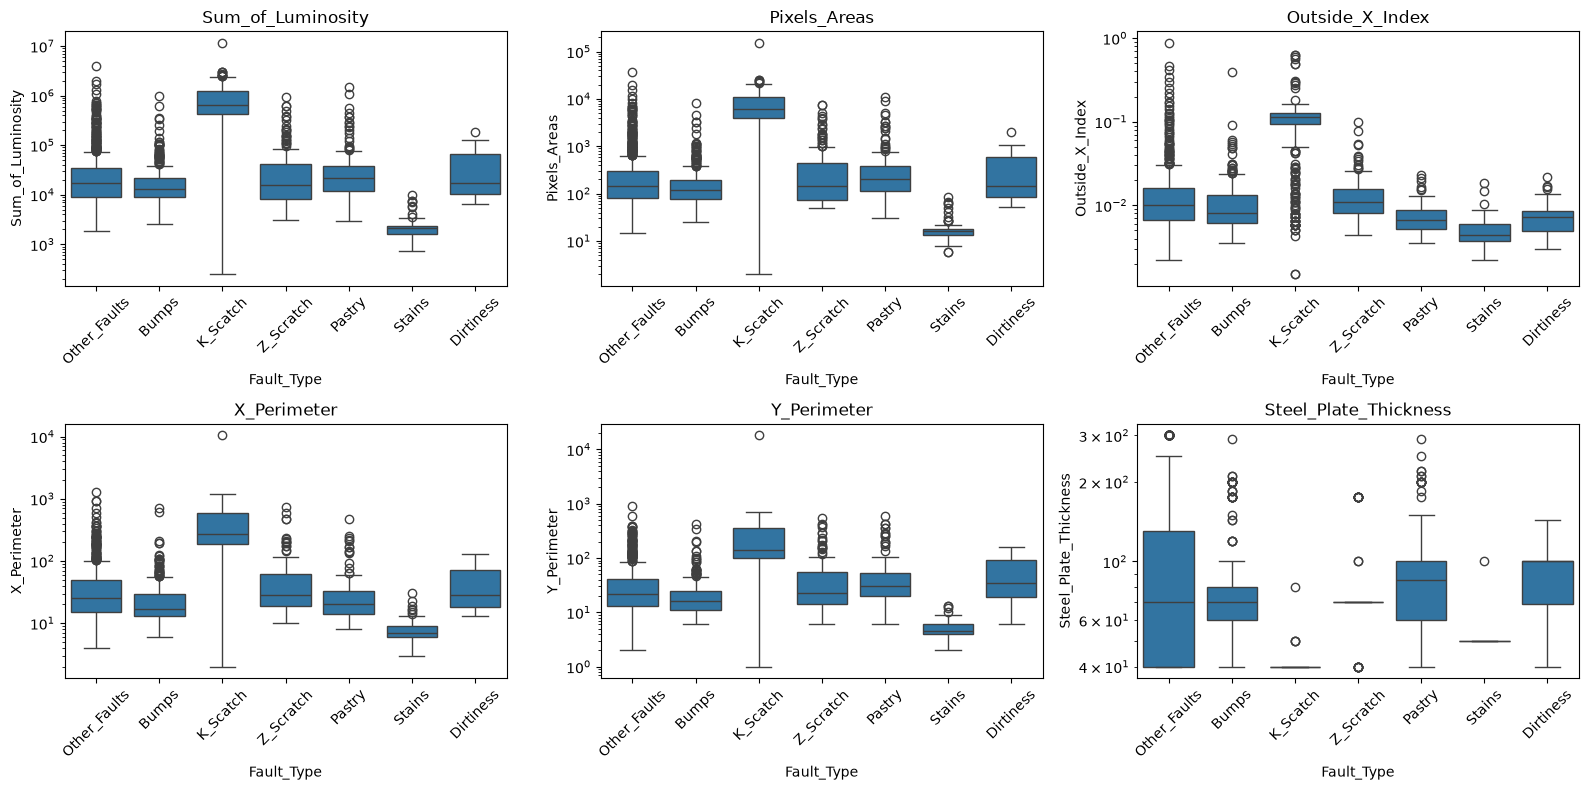

,위반 건수
X_Minimum <= X_Maximum,0
Y_Minimum <= Y_Maximum,0
면적 > 0,0
면적 <= 외접 사각형 넓이,0
X_Perimeter >= 가로 폭,0
Y_Perimeter >= 세로 길이,0
X_Maximum <= 컨베이어 길이,0
최소 밝기 <= 최대 밝기,0
밝기 0~255,0
밝기 합계가 면적×최소~최대 밝기 사이,2



[위반] 밝기 합계가 면적×최소~최대 밝기 사이


,Fault_Type,Pixels_Areas,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity
518,K_Scatch,5357,764,123,134
591,K_Scatch,5993,589956,132,132


,Fault_Type,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Outside_X_Index,Steel_Plate_Thickness
391,K_Scatch,152655,10449,18152,11591414,0.1123,40
1592,Other_Faults,37334,908,903,3918209,0.0966,40
394,K_Scatch,25473,992,578,3061597,0.1607,40
392,K_Scatch,25323,1022,593,3037459,0.1643,40
395,K_Scatch,24365,1084,680,2935414,0.3105,40
398,K_Scatch,22554,999,605,2712104,0.1579,40
399,K_Scatch,21987,1050,684,2638402,0.1595,40
393,K_Scatch,21110,1138,597,2554885,0.1569,40
400,K_Scatch,21036,1015,586,2519511,0.2739,40
396,K_Scatch,20894,1169,712,2529140,0.1602,40


두께 IQR 상한: 140.0


Fault_Type,Bumps,Dirtiness,K_Scatch,Other_Faults,Pastry,Stains,Z_Scratch,합계
Steel_Plate_Thickness,,,,,,,,
40,78,12,387,191,34,0,8,710
50,14,1,3,21,5,71,0,115
60,60,0,0,14,13,0,0,87
69,12,8,0,15,4,0,0,39
70,70,0,0,121,19,0,170,380
80,91,0,1,54,4,0,0,150
85,4,0,0,0,0,0,0,4
90,0,0,0,1,22,0,0,23
100,38,27,0,68,18,1,2,154


In [1]:
# %% [0] 준비: 데이터 불러오기, 목표 변수 합치기, 이상치 함수
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('steel_plates_faults.csv')

targets = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']
df['Fault_Type'] = df[targets].idxmax(axis=1).astype('category')

features = [c for c in df.columns if c not in targets + ['Fault_Type', 'TypeOfSteel']]
binary = ['TypeOfSteel_A300', 'TypeOfSteel_A400']
num_cols = [c for c in features if c not in binary]          # 25개

def iqr_mask(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return (s < lo) | (s > hi), lo, hi


# %% [1] 변수별 분포 요약: 치우침(skew)과 로그 변환 후 이상치 수 비교
rows = []
for c in num_cols:
    s = df[c]
    m, lo, hi = iqr_mask(s)
    row = {'컬럼': c, '고유값 수': s.nunique(), '왜도': round(s.skew(), 2),
           '이상치 건수': int(m.sum()), '이상치 비율(%)': round(m.mean() * 100, 2),
           '하한': round(lo, 3), '상한': round(hi, 3)}
    if (s > 0).all():                                       # 양수 변수만 로그 비교
        m_log, _, _ = iqr_mask(np.log10(s))
        row['로그 후 이상치'] = int(m_log.sum())
    rows.append(row)

summary = pd.DataFrame(rows).sort_values('이상치 건수', ascending=False)
display(summary)
# 해석: 왜도가 크고 로그 후 이상치가 크게 줄면 → 오류보다 '치우친 분포'에서 생긴 이상치


# %% [2] 원래 분포 vs 로그 분포 (IQR 경계선 표시)
check_cols = ['Sum_of_Luminosity', 'Pixels_Areas', 'Outside_X_Index',
              'X_Perimeter', 'Y_Perimeter', 'Steel_Plate_Thickness']

fig, axes = plt.subplots(len(check_cols), 2, figsize=(12, 3 * len(check_cols)))
for i, c in enumerate(check_cols):
    _, lo, hi = iqr_mask(df[c])
    sns.histplot(df[c], bins=50, ax=axes[i, 0])
    axes[i, 0].axvline(hi, color='red', ls='--', label='IQR upper')
    axes[i, 0].set_title(f'{c} (raw)')
    axes[i, 0].legend()

    s_log = np.log10(df[c])
    _, lo_l, hi_l = iqr_mask(s_log)
    sns.histplot(s_log, bins=50, ax=axes[i, 1])
    for v in (lo_l, hi_l):
        axes[i, 1].axvline(v, color='red', ls='--')
    axes[i, 1].set_title(f'log10({c})')
plt.tight_layout()
plt.show()


# %% [3] 이상치가 특정 결함 유형에 몰려 있는가
flag = pd.DataFrame({c: iqr_mask(df[c])[0] for c in num_cols})
df['has_outlier'] = flag.any(axis=1)

by_type = pd.DataFrame({
    '전체 건수': df['Fault_Type'].value_counts(),
    '이상치 보유 건수': df.loc[df['has_outlier'], 'Fault_Type'].value_counts(),
}).fillna(0).astype(int)
by_type['유형 내 이상치 비율(%)'] = (by_type['이상치 보유 건수'] / by_type['전체 건수'] * 100).round(1)
display(by_type.sort_values('유형 내 이상치 비율(%)', ascending=False))

# 변수별로 이상치가 어느 유형에서 나왔는지
comp = pd.DataFrame({c: df.loc[flag[c], 'Fault_Type'].value_counts(normalize=True)
                     for c in check_cols}).T.mul(100).round(1)
display(comp)


# %% [4] 결함 유형별 분포 (로그 축 박스플롯)
order = df['Fault_Type'].value_counts().index
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), check_cols):
    sns.boxplot(data=df, x='Fault_Type', y=c, order=order, ax=ax)
    if (df[c] > 0).all():
        ax.set_yscale('log')
    ax.set_title(c)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
# 해석: 특정 유형의 상자 전체가 위쪽에 있으면 → 그 유형의 특징


# %% [5] 물리적 의미 점검: 값들이 서로 모순되지 않는가
w = df['X_Maximum'] - df['X_Minimum']          # 결함 가로 폭
h = df['Y_Maximum'] - df['Y_Minimum']          # 결함 세로 길이
area = df['Pixels_Areas']

rules = {
    'X_Minimum <= X_Maximum': df['X_Minimum'] <= df['X_Maximum'],
    'Y_Minimum <= Y_Maximum': df['Y_Minimum'] <= df['Y_Maximum'],
    '면적 > 0': area > 0,
    '면적 <= 외접 사각형 넓이': area <= (w + 1) * (h + 1),
    'X_Perimeter >= 가로 폭': df['X_Perimeter'] >= w,
    'Y_Perimeter >= 세로 길이': df['Y_Perimeter'] >= h,
    'X_Maximum <= 컨베이어 길이': df['X_Maximum'] <= df['Length_of_Conveyer'],
    '최소 밝기 <= 최대 밝기': df['Minimum_of_Luminosity'] <= df['Maximum_of_Luminosity'],
    '밝기 0~255': df['Minimum_of_Luminosity'].ge(0) & df['Maximum_of_Luminosity'].le(255),
    '밝기 합계가 면적×최소~최대 밝기 사이':
        df['Sum_of_Luminosity'].between(area * df['Minimum_of_Luminosity'],
                                        area * df['Maximum_of_Luminosity']),
    'LogOfAreas = log10(면적)': np.isclose(df['LogOfAreas'], np.log10(area), atol=1e-3),
}
rule_result = pd.DataFrame({'위반 건수': {k: int((~v).sum()) for k, v in rules.items()}})
display(rule_result)

# 위반 행이 있으면 직접 확인
for k, v in rules.items():
    if (~v).any():
        print(f'\n[위반] {k}')
        display(df.loc[~v, ['Fault_Type', 'Pixels_Areas', 'Sum_of_Luminosity',
                            'Minimum_of_Luminosity', 'Maximum_of_Luminosity']])


# %% [6] 극단값 상위 행 확인: 큰 값이 '큰 결함'으로 일관되게 설명되는가
cols_view = ['Fault_Type', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter',
             'Sum_of_Luminosity', 'Outside_X_Index', 'Steel_Plate_Thickness']
display(df.nlargest(10, 'Pixels_Areas')[cols_view])
# 면적이 큰 행은 둘레·밝기 합계·Outside_X_Index도 함께 커야 정상 (한 변수만 튀면 오류 의심)


# %% [7] 강판 두께: 결함 특성이 아닌 강판 속성 → 값별·유형별 빈도
_, _, hi_t = iqr_mask(df['Steel_Plate_Thickness'])
print(f'두께 IQR 상한: {hi_t}')
display(pd.crosstab(df['Steel_Plate_Thickness'], df['Fault_Type'],
                    margins=True, margins_name='합계'))